# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  879M    0  879M    0     0  10.5M      0 --:--:--  0:01:23 --:--:-- 16.9M


In [2]:
#!rm SUSY.csv

In [2]:
#!gunzip SUSY.csv.gz

In [3]:
!ls -lh

total 2.3G
-rw-rw-r-- 1 lenvel lenvel 357K Nov 16 18:54 Lab.7.Submission.ipynb
-rw-rw-r-- 1 lenvel lenvel 2.3G Nov 16 18:50 SUSY.csv


The data is provided as a comma separated file.

In [4]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

We see that we have 5 million datapoints.

In [5]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [6]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

In [7]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [8]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [9]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [10]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [11]:
FeatureNames

['S_R',
 'M_TR_2',
 'axial_MET',
 'MT2',
 'cos_theta_r1',
 'dPhi_r_b',
 'R',
 'MET_rel',
 'M_Delta_R',
 'M_R']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [13]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [14]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [15]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


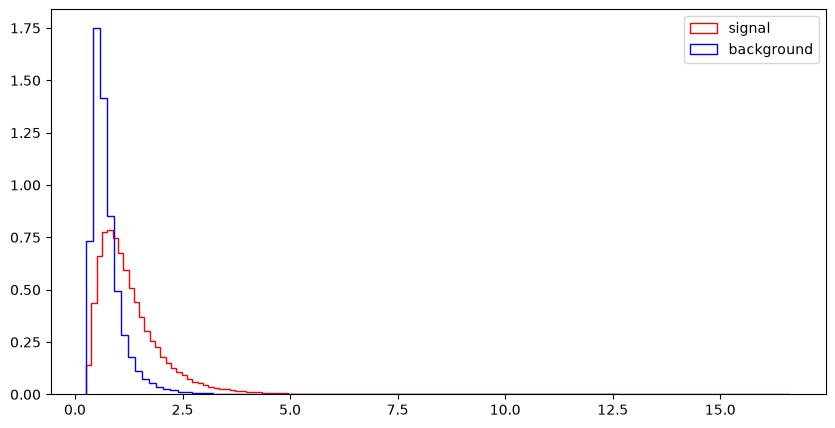

l_1_eta


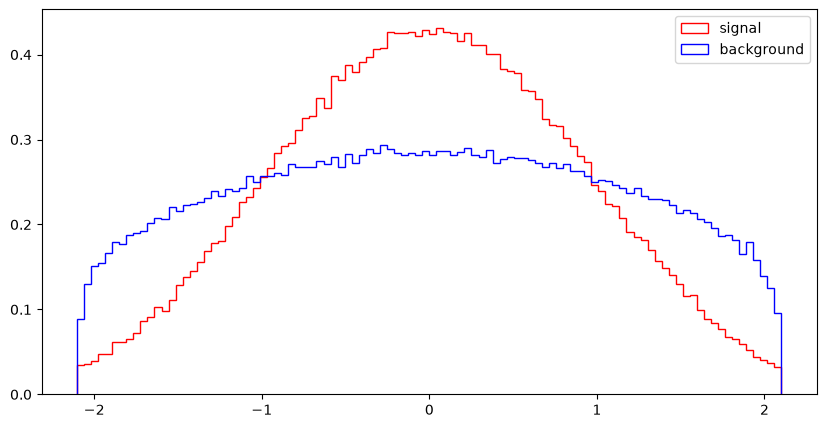

l_1_phi


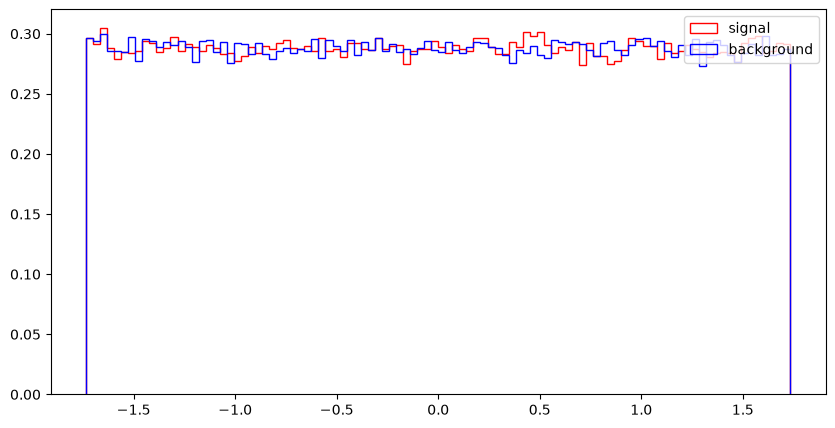

l_2_pT


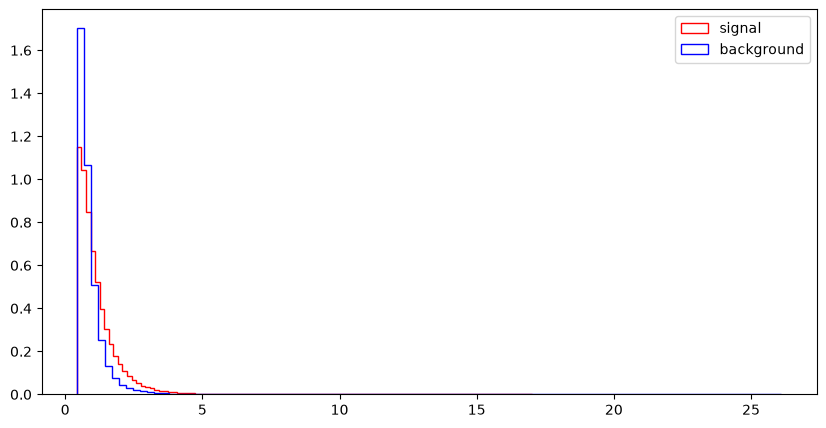

l_2_eta


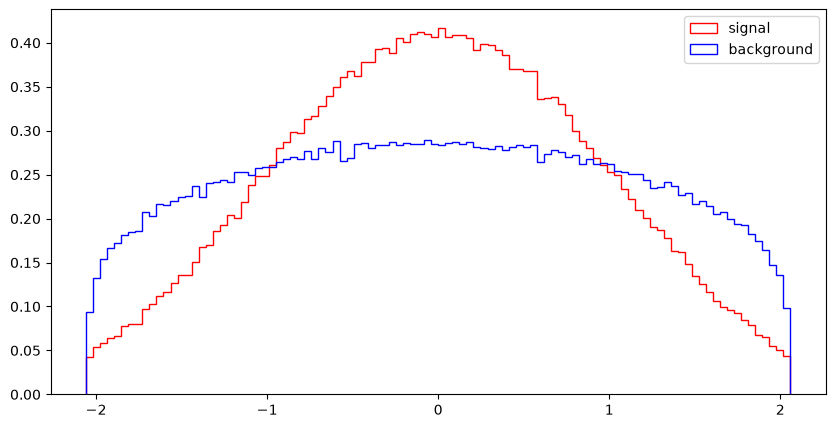

l_2_phi


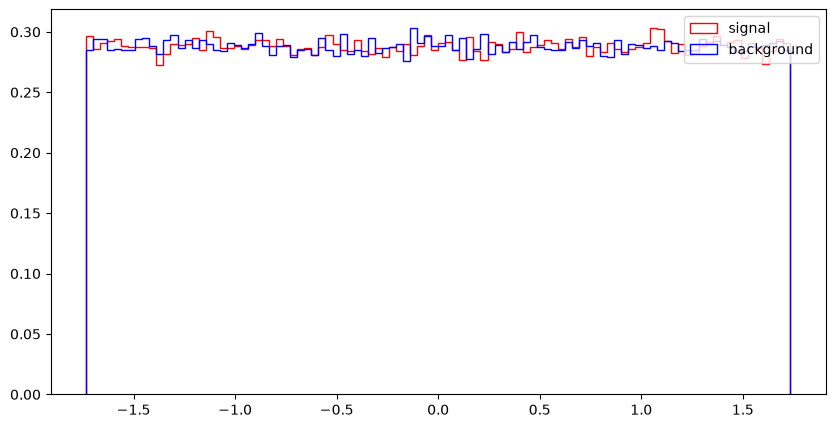

MET


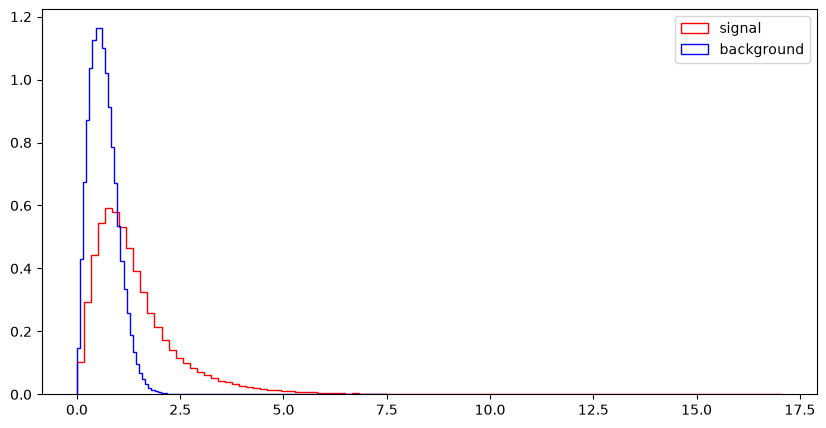

MET_phi


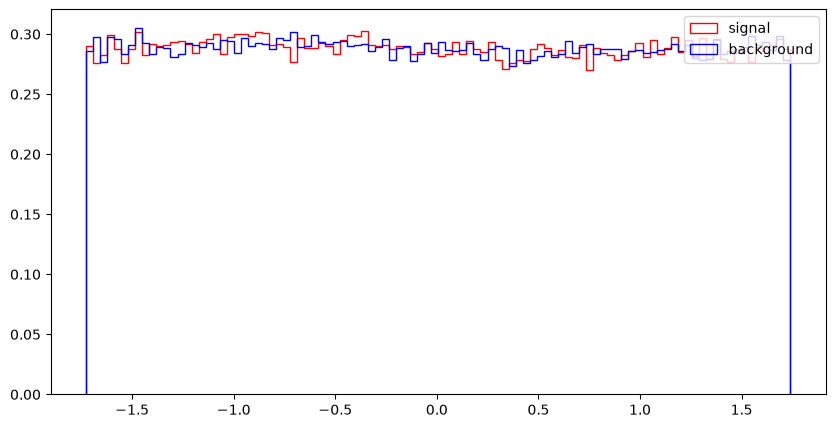

MET_rel


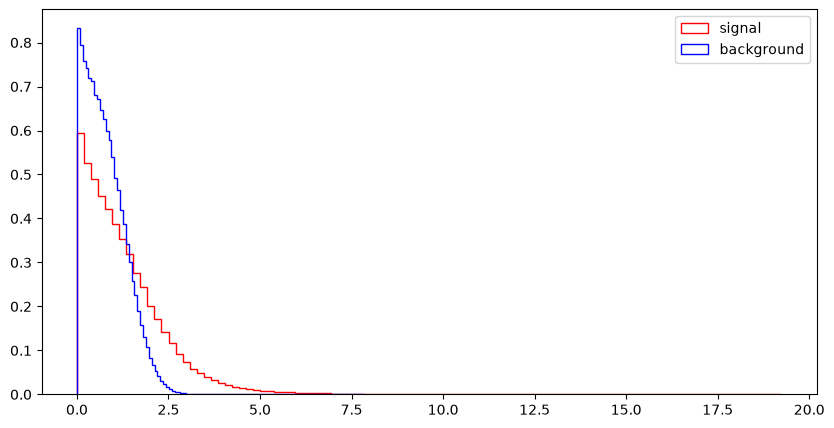

axial_MET


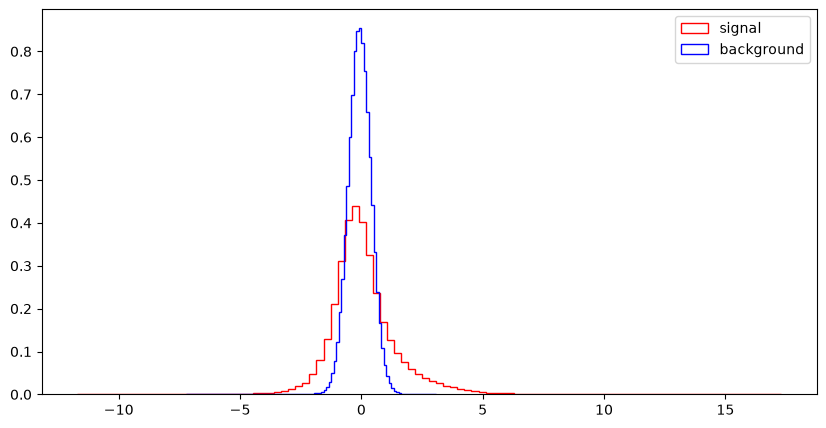

M_R


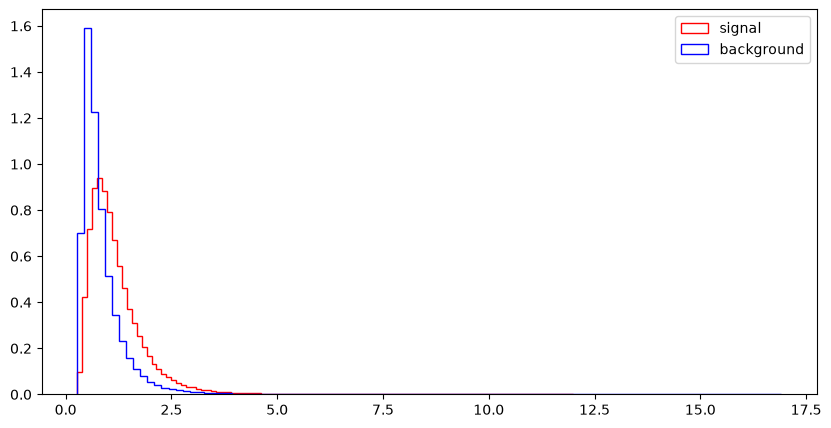

M_TR_2


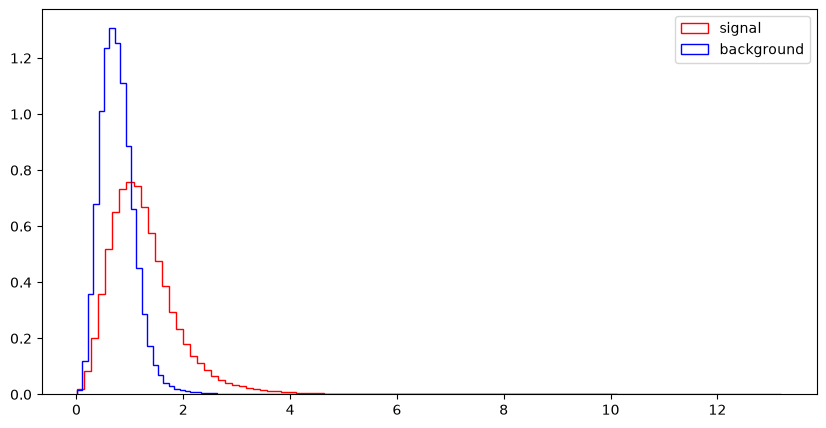

R


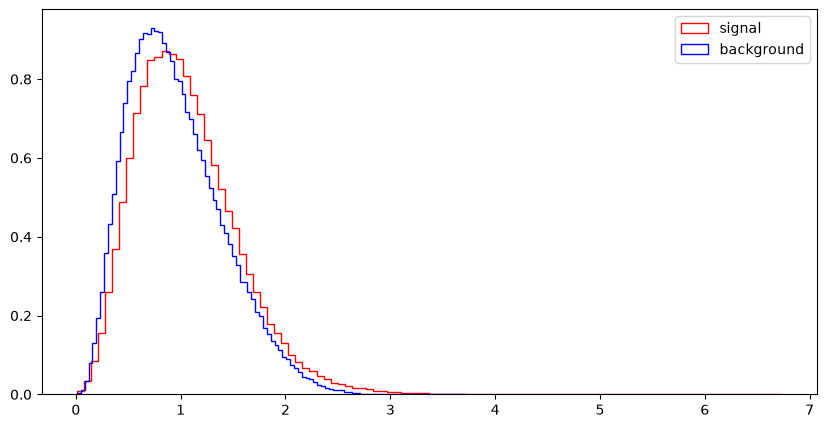

MT2


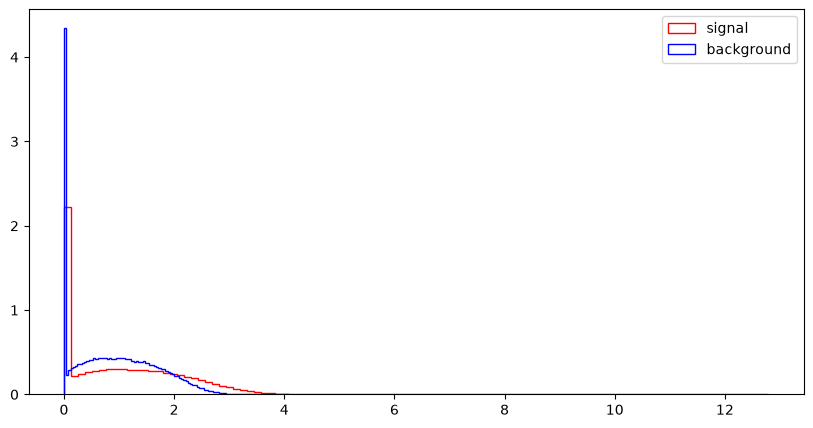

S_R


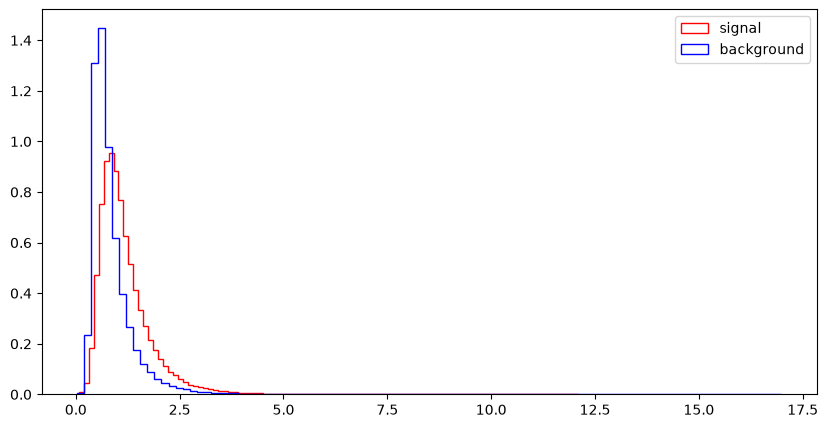

M_Delta_R


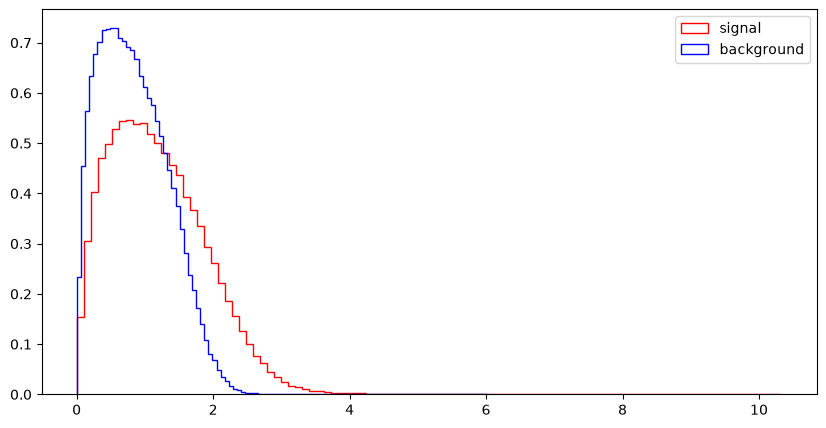

dPhi_r_b


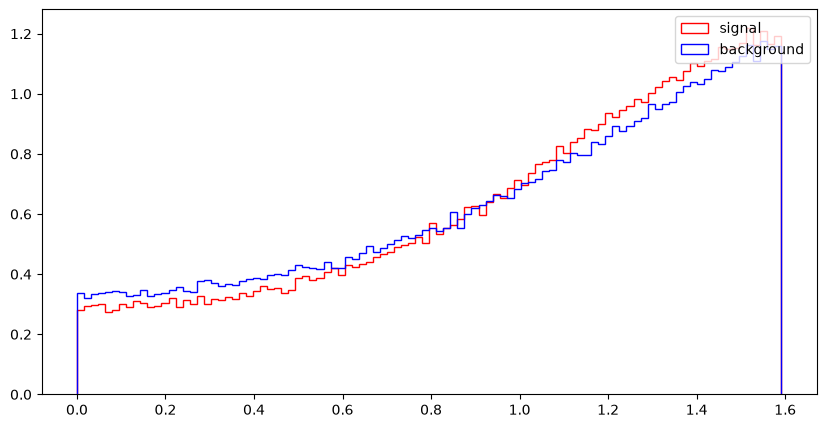

cos_theta_r1


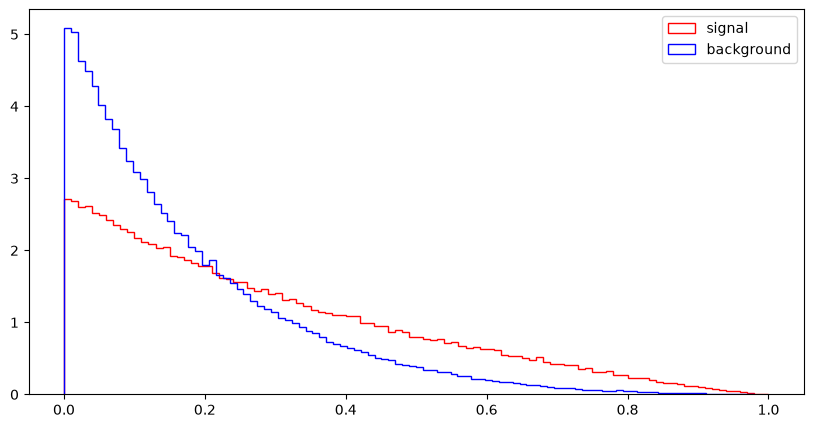

In [16]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

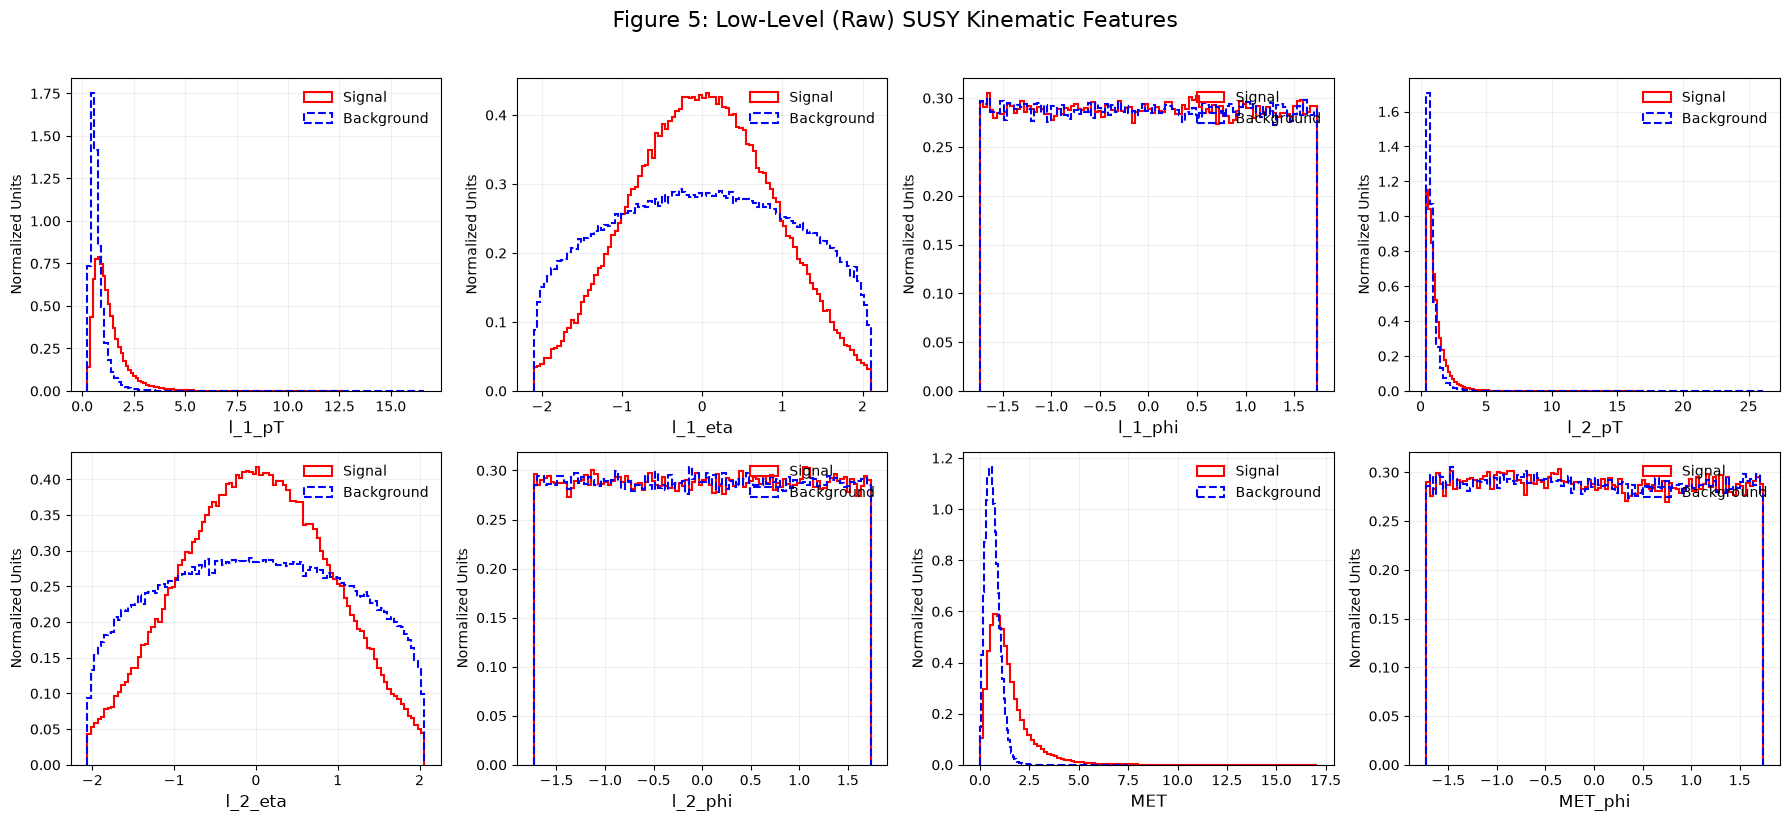

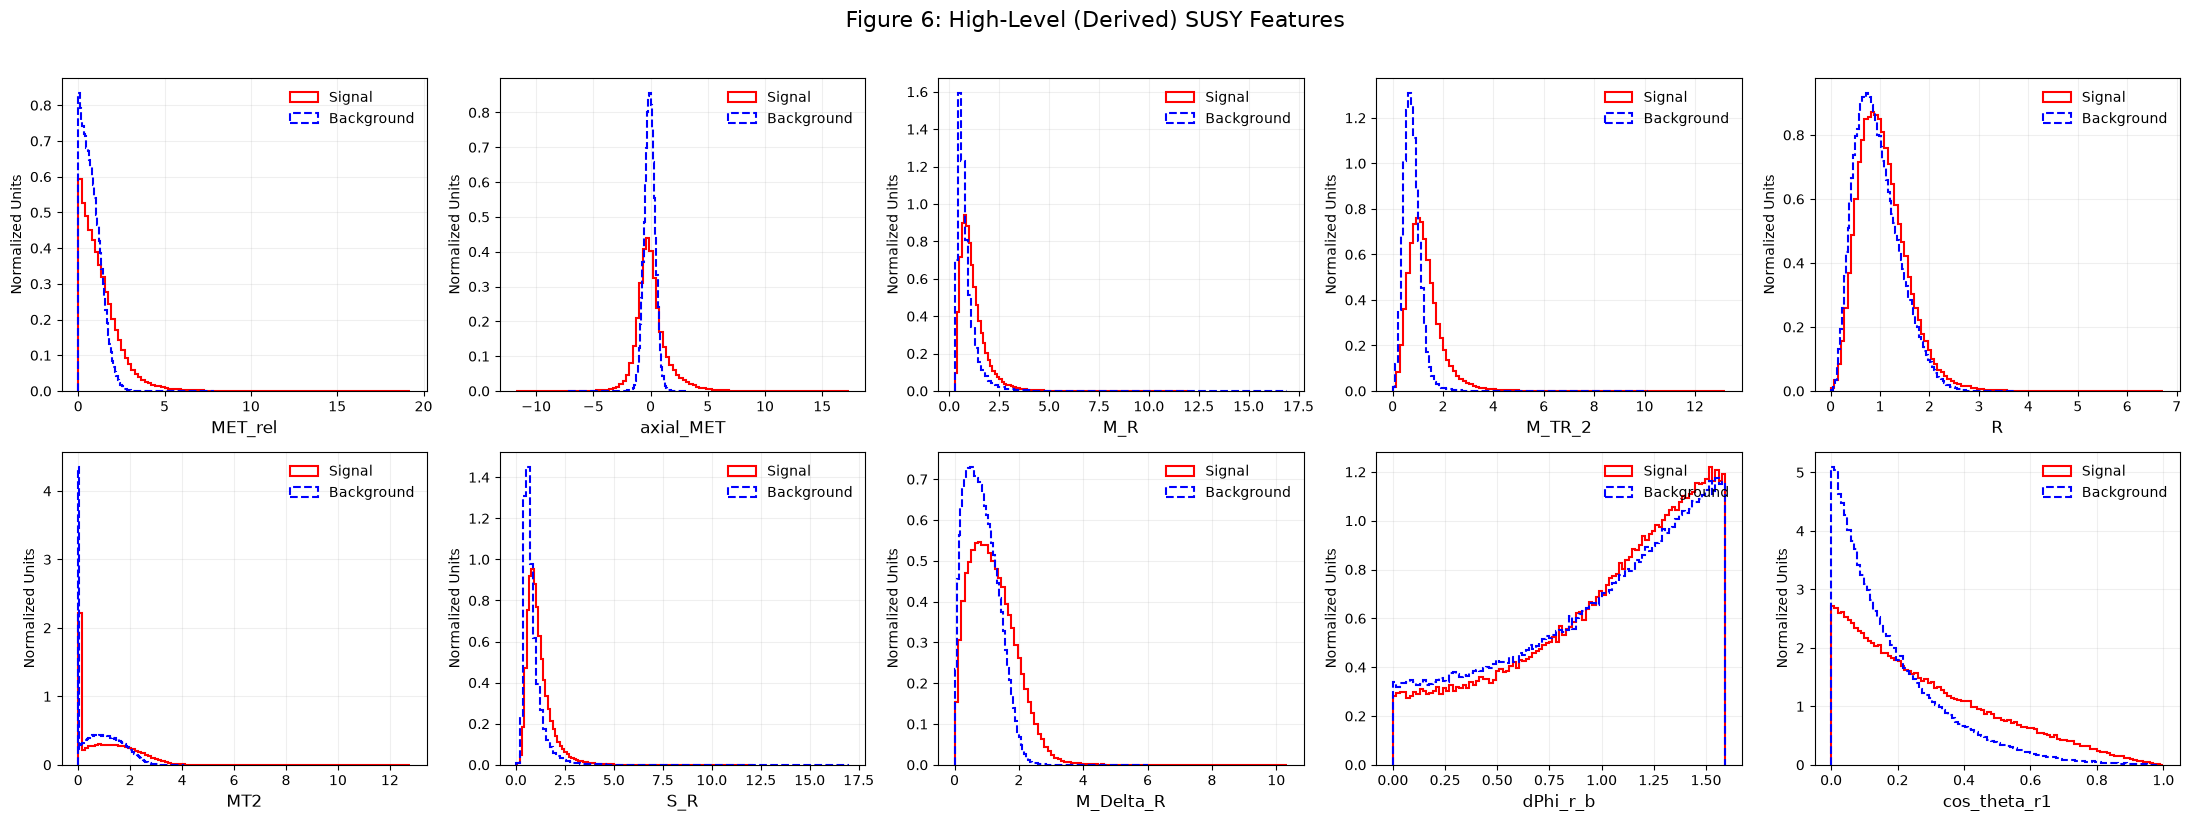

In [17]:

OrderedFeatureNames = [v for v in VarNames[1:] if v not in RawNames]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, var in enumerate(RawNames):
    axes[i].hist(df_sig[var], bins=100, histtype="step", color="red", label="Signal", density=True, linewidth=1.5)
    axes[i].hist(df_bkg[var], bins=100, histtype="step", color="blue", label="Background", density=True, linestyle="--", linewidth=1.5)
    axes[i].set_xlabel(var, fontsize=12)
    axes[i].set_ylabel("Normalized Units", fontsize=10)
    axes[i].legend(loc="upper right", frameon=False)
    axes[i].grid(alpha=0.2)

plt.suptitle("Figure 5: Low-Level (Raw) SUSY Kinematic Features", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for i, var in enumerate(OrderedFeatureNames):
    axes[i].hist(df_sig[var], bins=100, histtype="step", color="red", label="Signal", density=True, linewidth=1.5)
    axes[i].hist(df_bkg[var], bins=100, histtype="step", color="blue", label="Background", density=True, linestyle="--", linewidth=1.5)
    axes[i].set_xlabel(var, fontsize=12)
    axes[i].set_ylabel("Normalized Units", fontsize=10)
    axes[i].legend(loc="upper right", frameon=False)
    axes[i].grid(alpha=0.2)

plt.suptitle("Figure 6: High-Level (Derived) SUSY Features", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

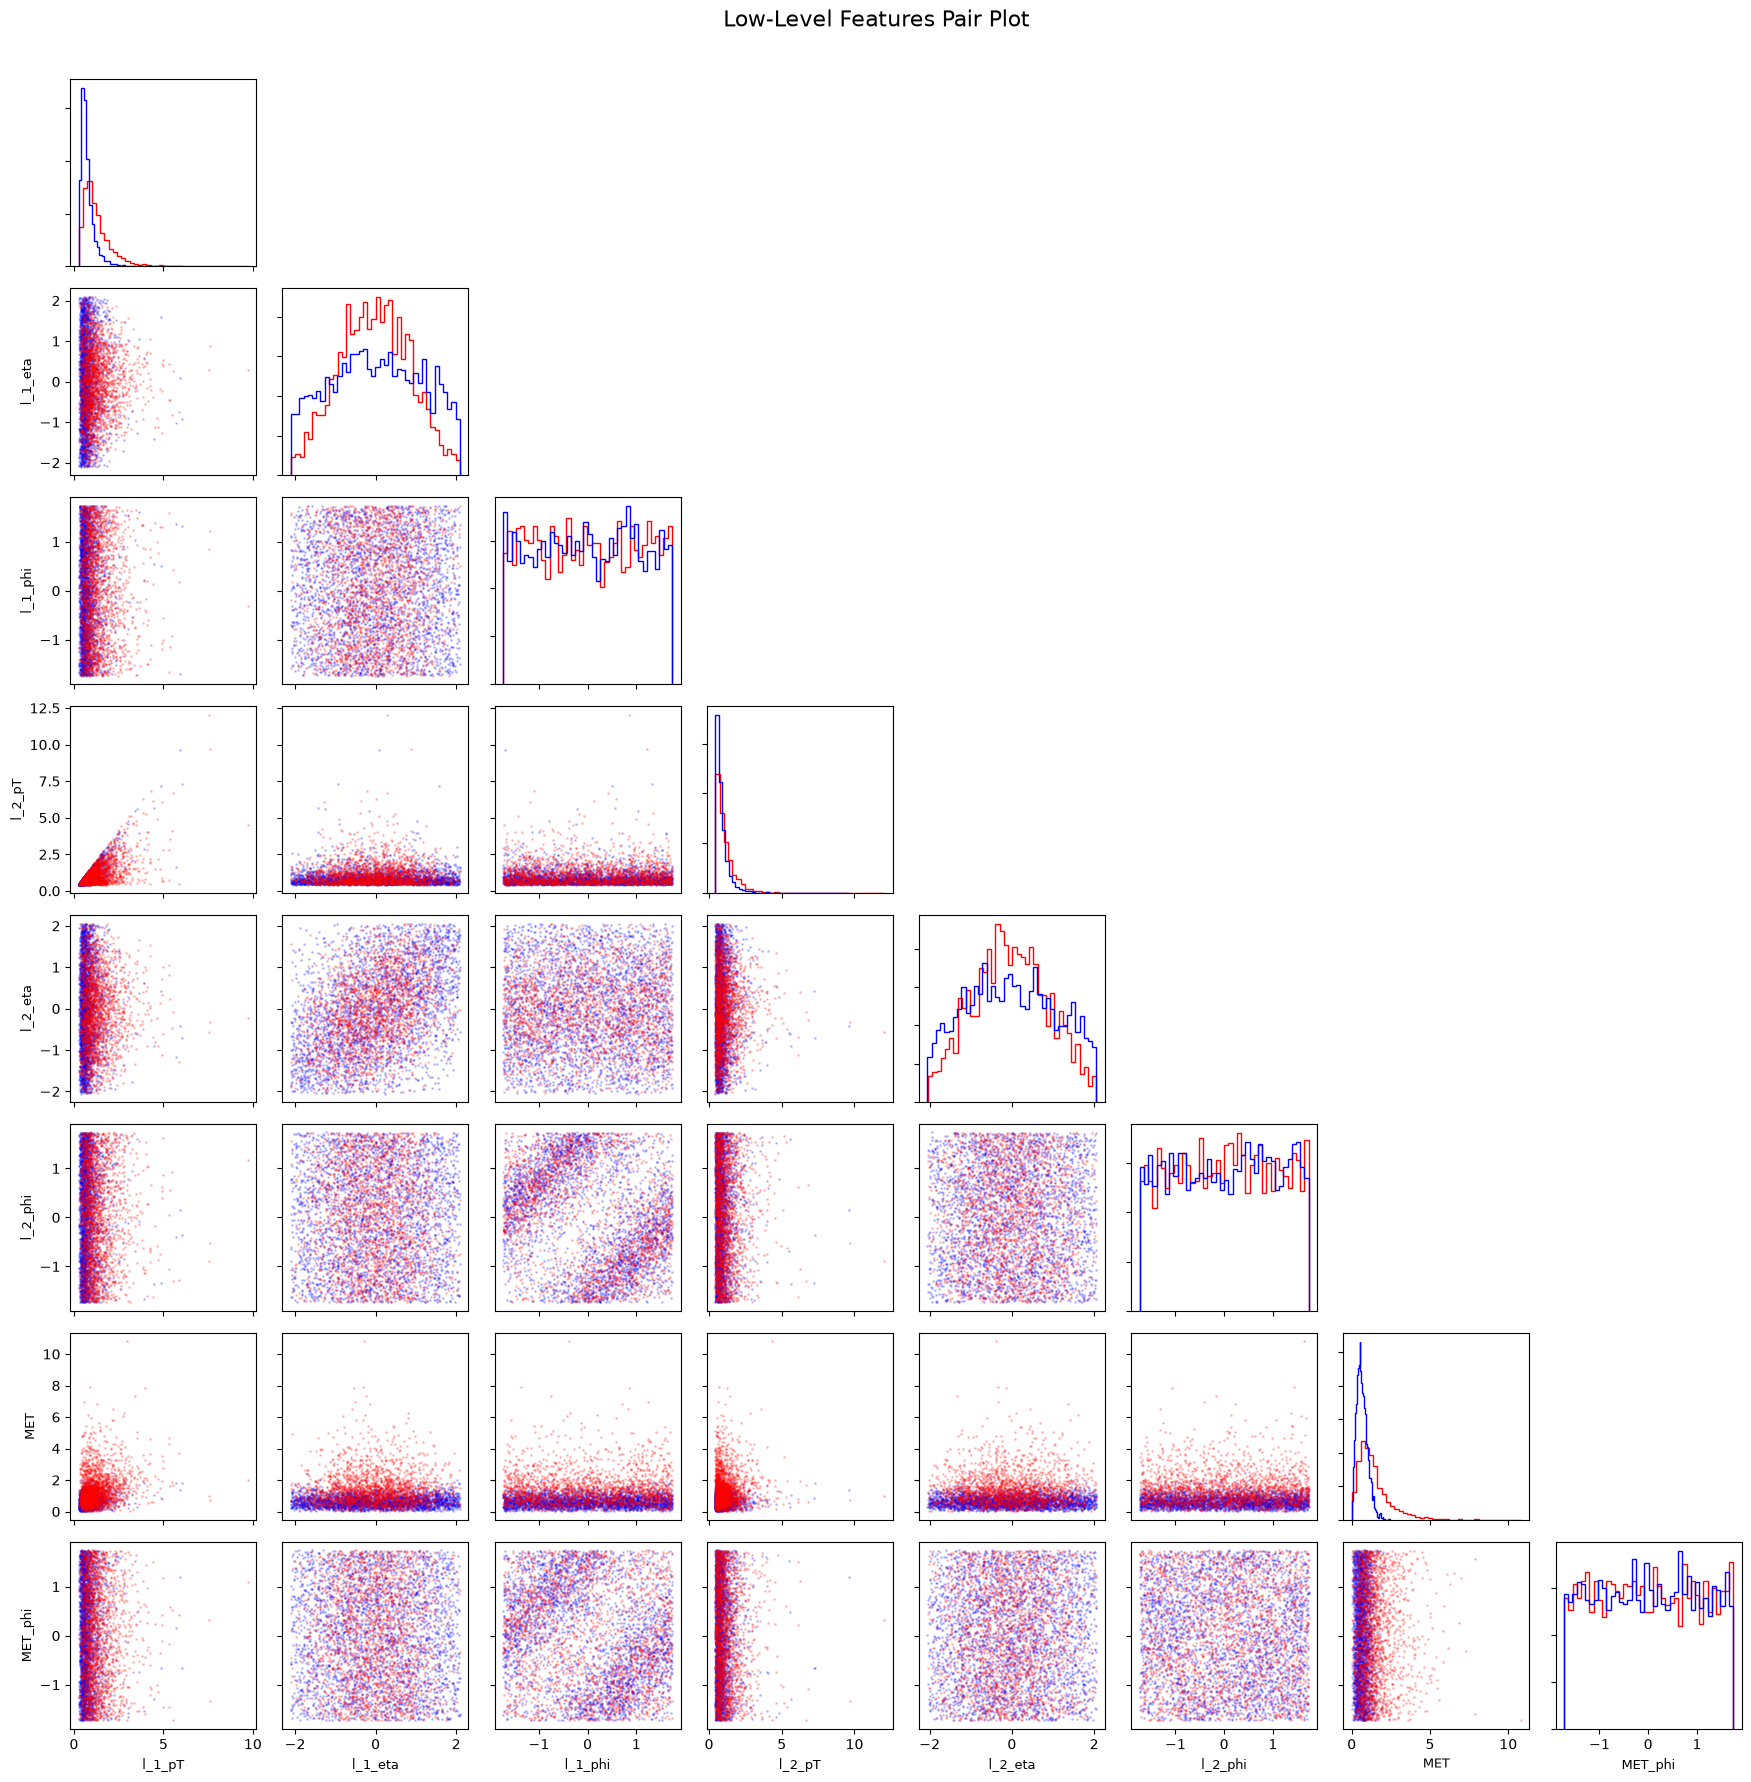

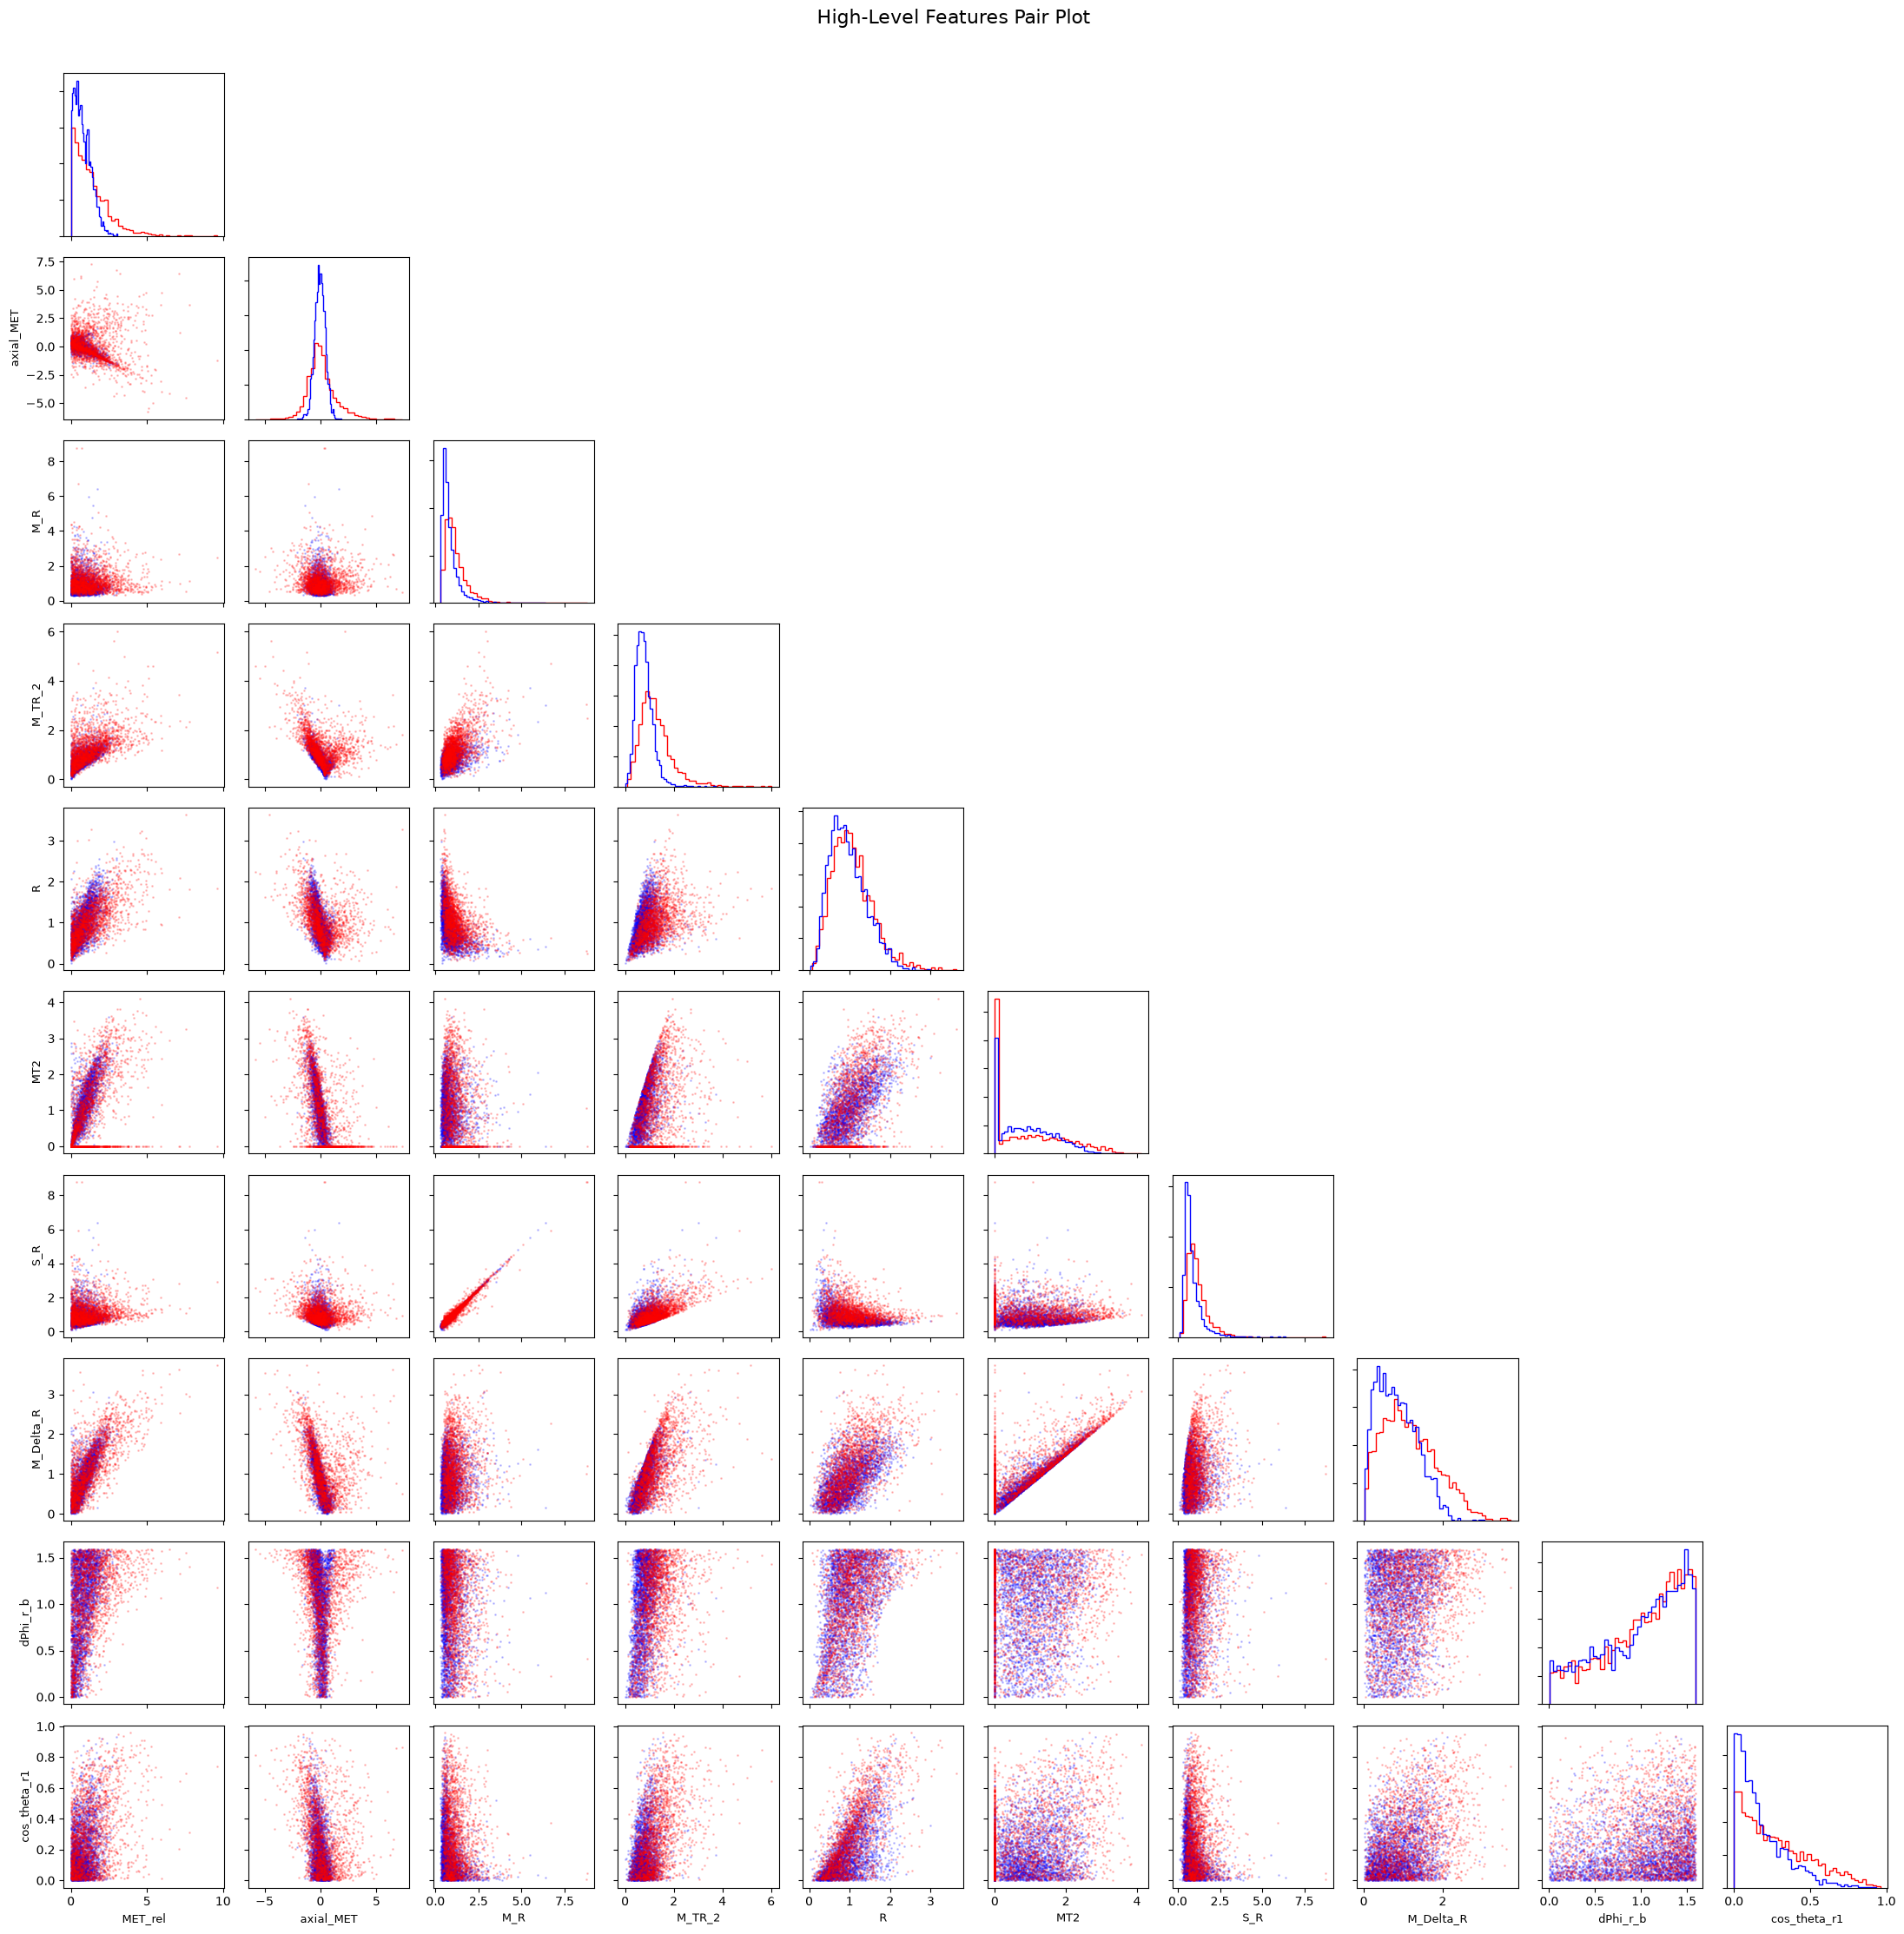

In [18]:

def fast_pairplot(df_sample, variables, sample_size=10000, bins=40, title="Pair Plot"):
    # Subsample for speed
    sub_df = df_sample.sample(n=min(sample_size, len(df_sample)), random_state=42)
    sig = sub_df[sub_df["signal"] == 1]
    bkg = sub_df[sub_df["signal"] == 0]
    
    n = len(variables)
    fig, axes = plt.subplots(n, n, figsize=(2.2 * n, 2.2 * n))
    
    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            if i == j:
            
                ax.hist(sig[variables[i]], bins=bins, histtype="step", color="red", density=True)
                ax.hist(bkg[variables[i]], bins=bins, histtype="step", color="blue", density=True)
            elif i > j:
               
                ax.scatter(bkg[variables[j]], bkg[variables[i]], color="blue", s=1, alpha=0.2, rasterized=True)
                ax.scatter(sig[variables[j]], sig[variables[i]], color="red", s=1, alpha=0.2, rasterized=True)
            else:
            
                ax.axis("off")
                
            if i == n - 1:
                ax.set_xlabel(variables[j], fontsize=9)
            else:
                ax.set_xticklabels([])
            if j == 0 and i > 0:
                ax.set_ylabel(variables[i], fontsize=9)
            else:
                ax.set_yticklabels([])
                
    plt.suptitle(title, fontsize=16, y=1.01)
    plt.tight_layout()
    plt.show()


fast_pairplot(df, RawNames, sample_size=5000, title="Low-Level Features Pair Plot")
fast_pairplot(df, OrderedFeatureNames, sample_size=5000, title="High-Level Features Pair Plot")

In [ ]:
#Part b Answer: Beyond subsampling and skipping the upper symmetric triangle, 
#you can pre-compute 1D and 2D bin counts in a single pass using numpy.histogram2d (or scipy.stats.binned_statistic_2d) on NumPy arrays and render them with ax.imshow() or ax.pcolormesh(), 
#which avoids creating thousands of individual Matplotlib patch/artist objects.

#Part c Answer: Looking at the 1D diagonals and 2D separations, the best observables for separating signal from background are MET (from the raw quantities) and M_TR_2, M_Delta_R, MET_rel,
#and R (from the derived features),
#as their signal distributions are shifted toward significantly higher values than the background.

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [ ]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

In [19]:

from IPython.display import HTML, display
import tabulate

def display_cov_corr(dataset, var_list, label="All Observables"):
    data_matrix = dataset[var_list].to_numpy().T
    
    cov_mat = np.cov(data_matrix)
    corr_mat = np.corrcoef(data_matrix)
    
    
    cov_table = [[var_list[i]] + [f"{val:.3f}" for val in cov_mat[i]] for i in range(len(var_list))]
    corr_table = [[var_list[i]] + [f"{val:.3f}" for val in corr_mat[i]] for i in range(len(var_list))]
    
    headers = ["Variable"] + var_list
    
    display(HTML(f"<h4>Covariance Matrix ({label})</h4>"))
    display(HTML(tabulate.tabulate(cov_table, headers=headers, tablefmt="html")))
    
    display(HTML(f"<h4>Correlation Matrix ({label})</h4>"))
    display(HTML(tabulate.tabulate(corr_table, headers=headers, tablefmt="html")))
    
    return cov_mat, corr_mat


cov_all, corr_all = display_cov_corr(df, VarNames[1:], "All 18 Observables")
cov_raw, corr_raw = display_cov_corr(df, RawNames, "Low-Level (Raw) Features")
cov_feat, corr_feat = display_cov_corr(df, OrderedFeatureNames, "High-Level (Derived) Features")

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

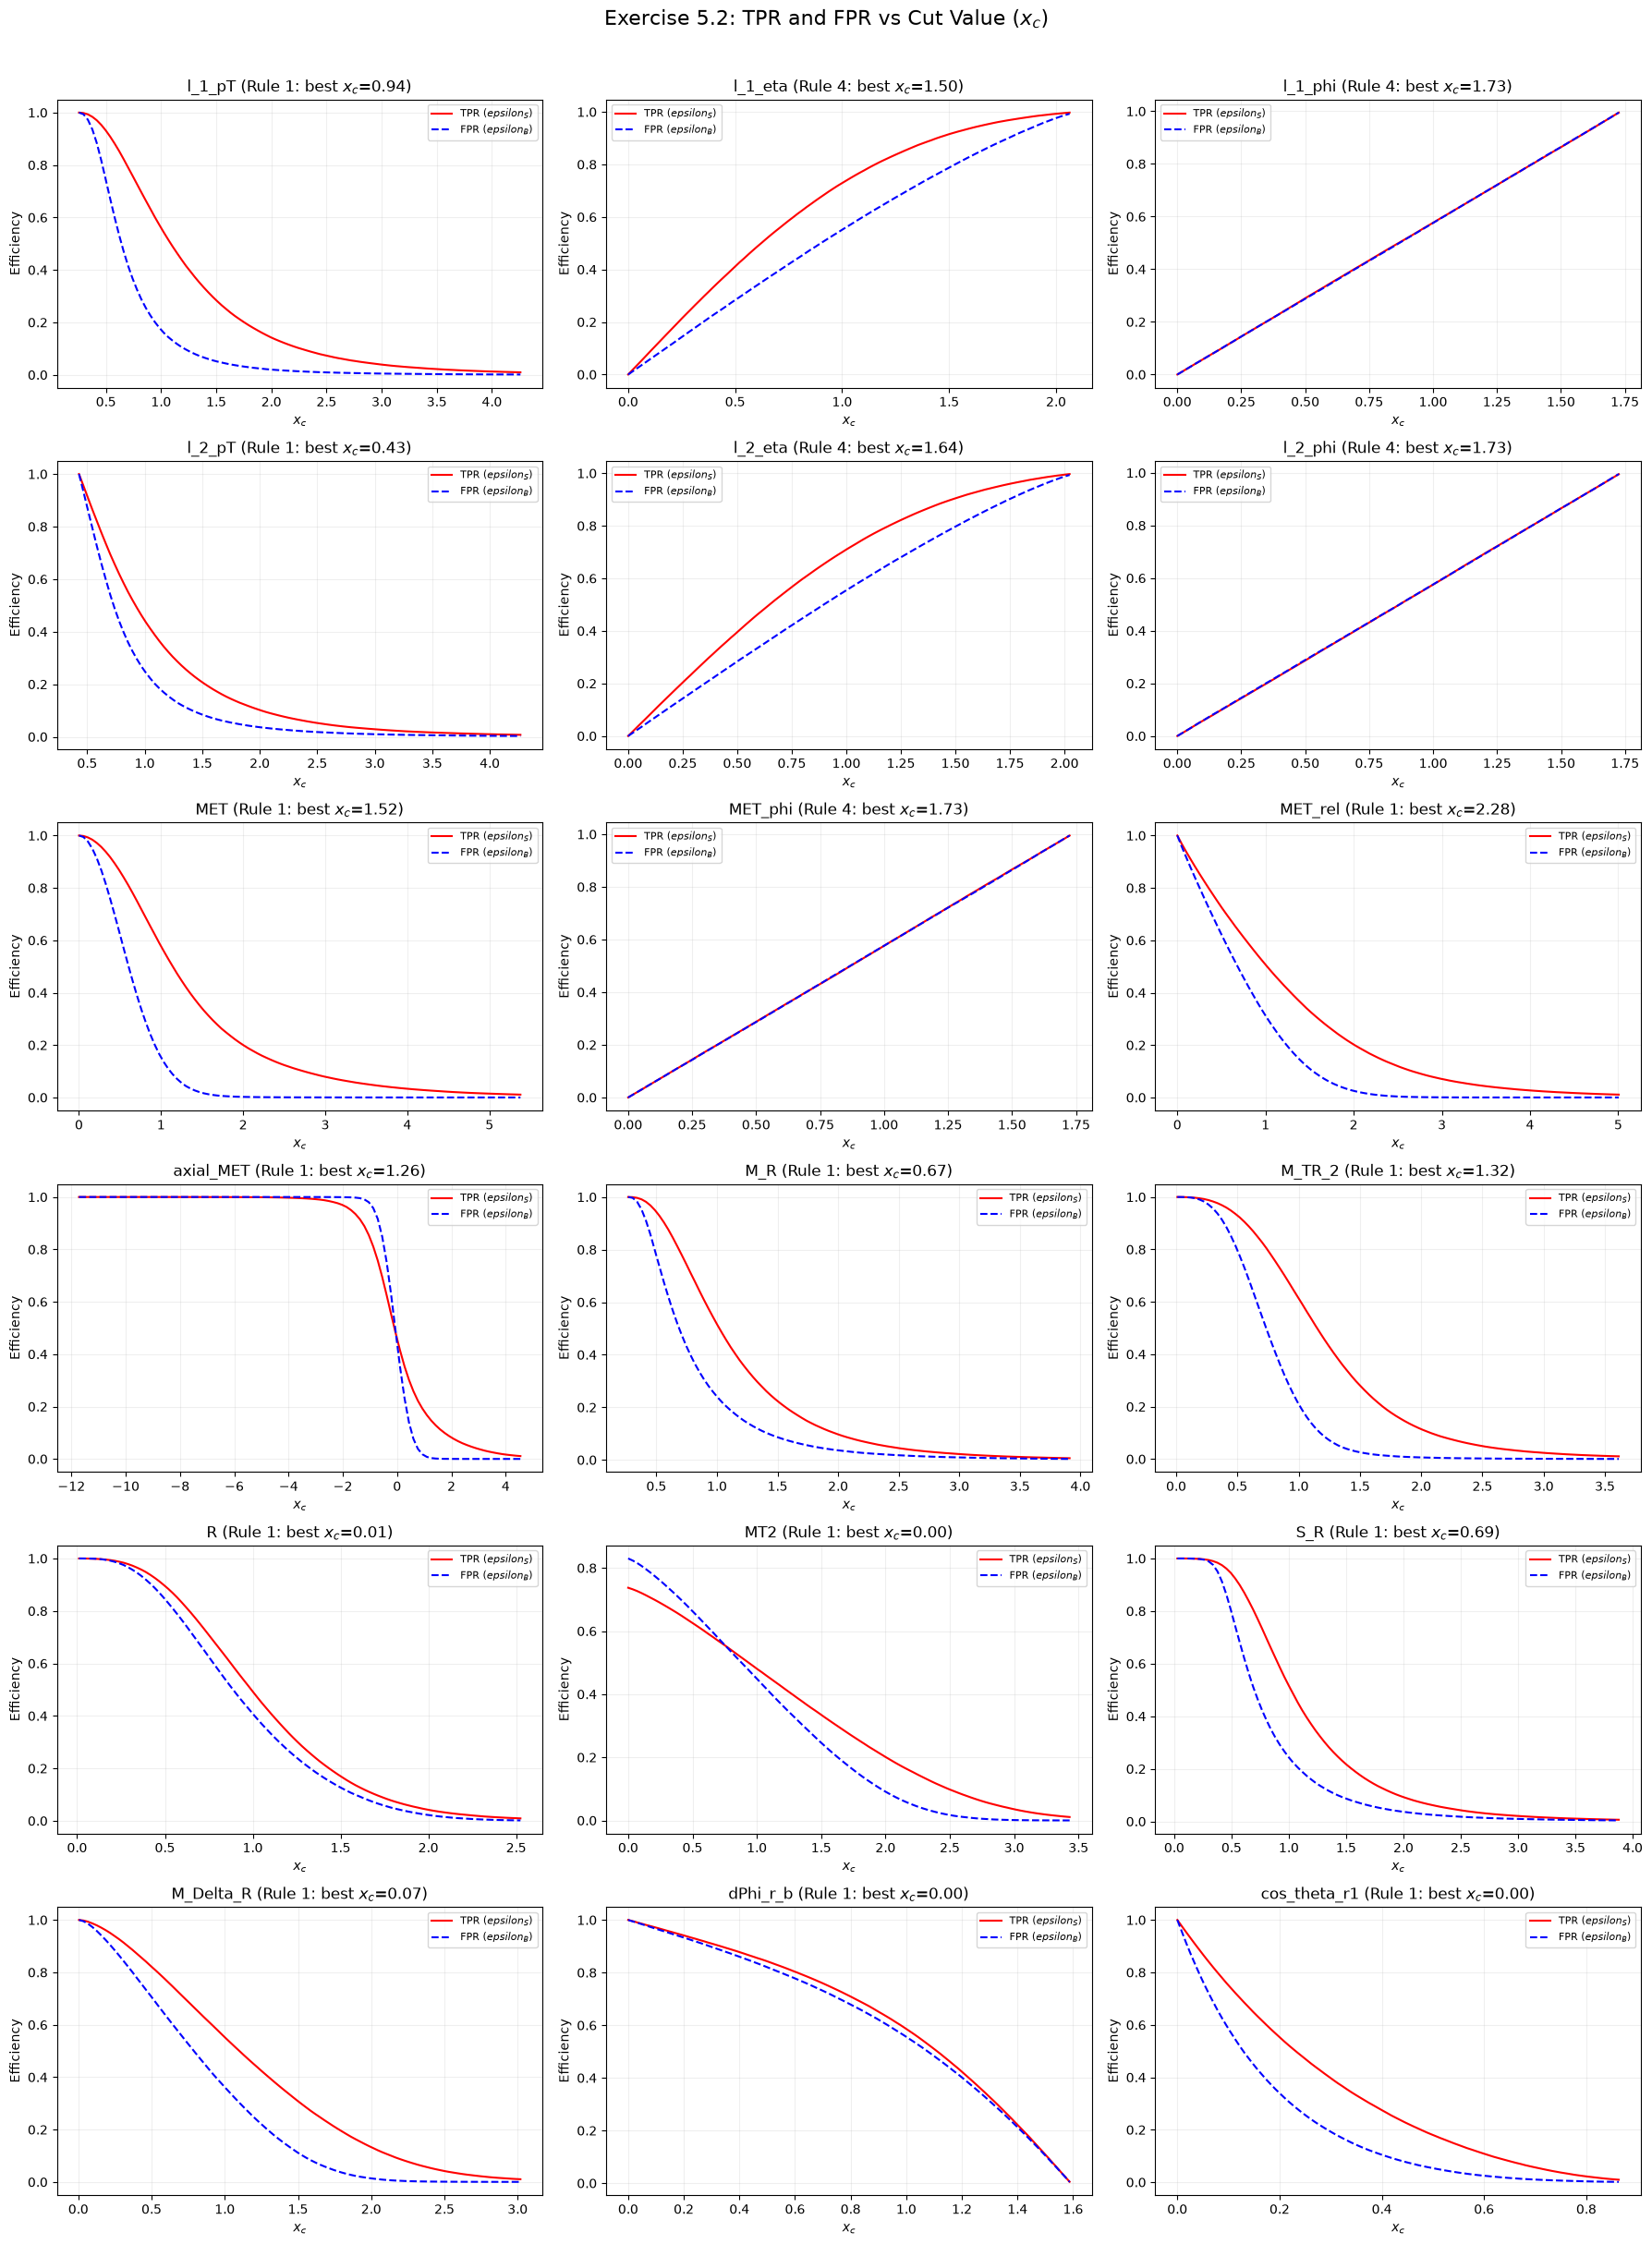

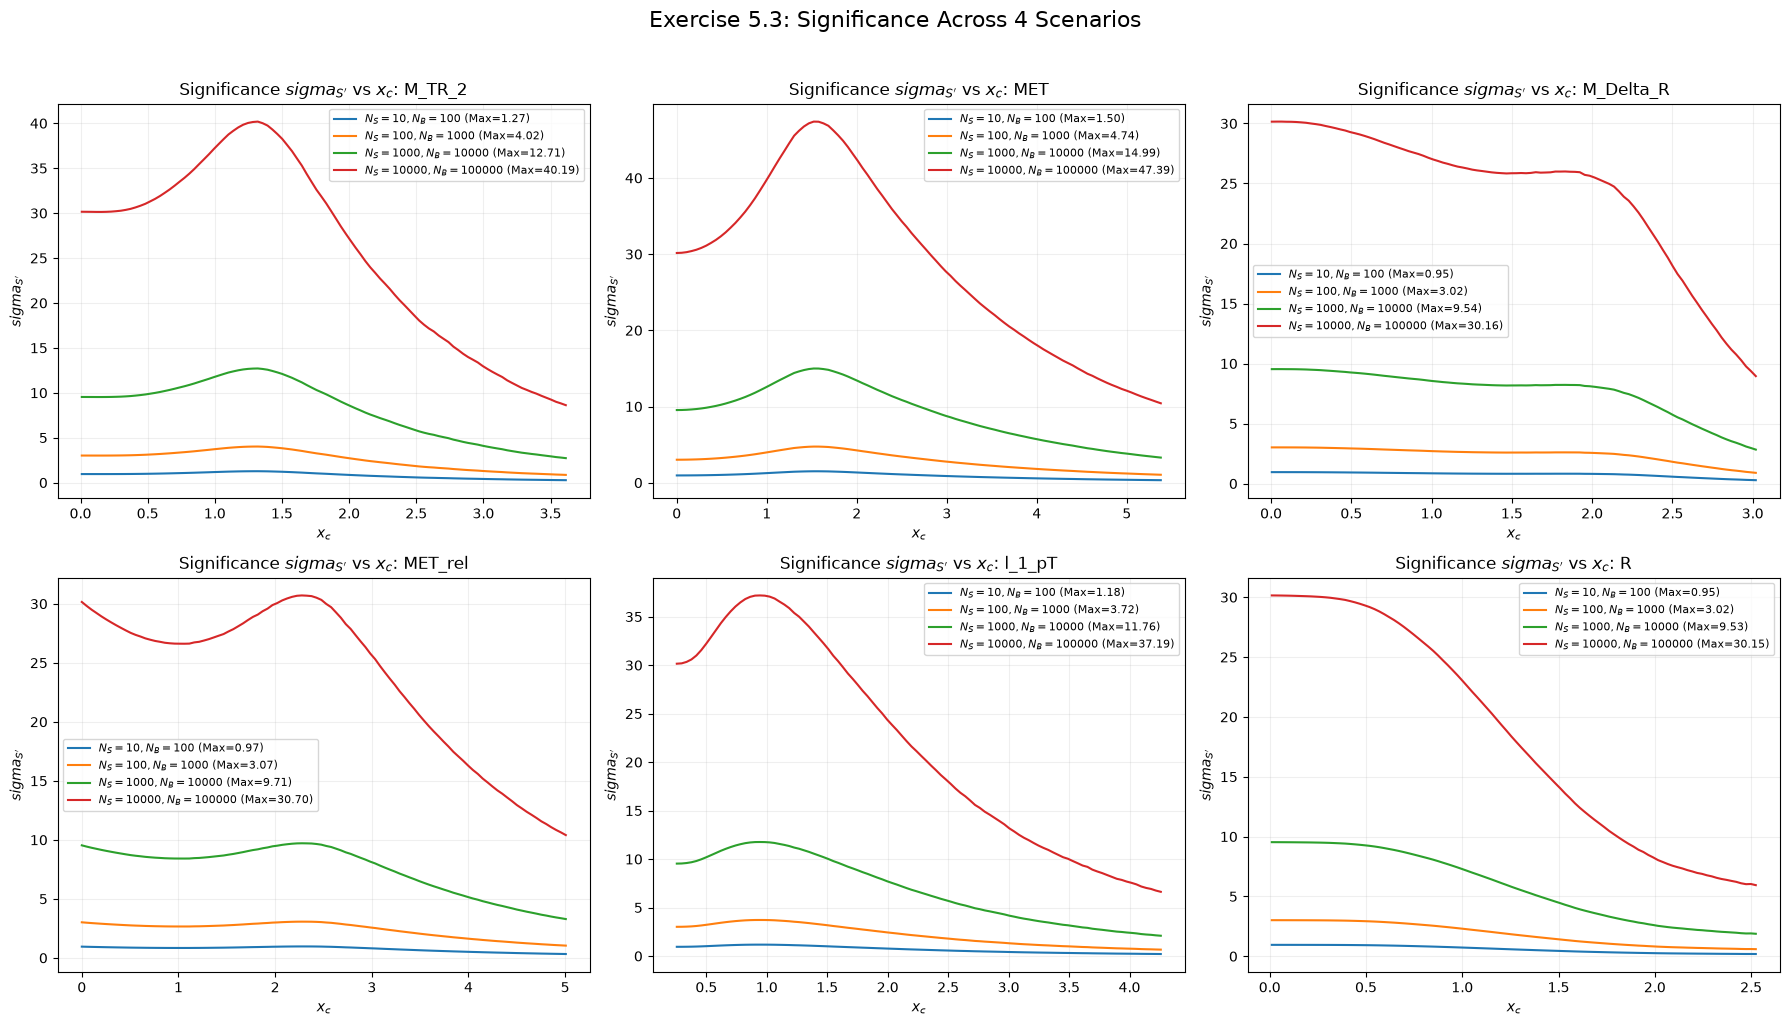

In [25]:


selection_rules = {
    "l_1_pT": 1, "l_1_eta": 4, "l_1_phi": 4, "l_2_pT": 1, "l_2_eta": 4, "l_2_phi": 4,
    "MET": 1, "MET_phi": 4, "MET_rel": 1, "axial_MET": 1, "M_R": 1, "M_TR_2": 1,
    "R": 1, "MT2": 1, "S_R": 1, "M_Delta_R": 1, "dPhi_r_b": 1, "cos_theta_r1": 1
}

def compute_efficiencies(df_sig, df_bkg, var, rule, n_cuts=100):
    s_vals = df_sig[var].to_numpy()
    b_vals = df_bkg[var].to_numpy()
    
    if rule in [3, 4]:
        mu = np.mean(np.concatenate([s_vals, b_vals]))
        s_vals = np.abs(s_vals - mu)
        b_vals = np.abs(b_vals - mu)
        
    min_val = min(s_vals.min(), b_vals.min())
    max_val = np.percentile(np.concatenate([s_vals, b_vals]), 99.5)
    cuts = np.linspace(min_val, max_val, n_cuts)
    
    tpr = np.zeros(n_cuts)
    fpr = np.zeros(n_cuts)
    
    for i, xc in enumerate(cuts):
        if rule in [1, 3]:  # > xc
            tpr[i] = np.mean(s_vals > xc)
            fpr[i] = np.mean(b_vals > xc)
        else:              # < xc
            tpr[i] = np.mean(s_vals < xc)
            fpr[i] = np.mean(b_vals < xc)
            
    return cuts, tpr, fpr


scenarios = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]
best_cuts_per_var = {}

fig, axes = plt.subplots(6, 3, figsize=(18, 24))
axes = axes.flatten()

for idx, var in enumerate(VarNames[1:]):
    rule = selection_rules[var]
    cuts, tpr, fpr = compute_efficiencies(df_sig, df_bkg, var, rule)
    
    ax = axes[idx]
    ax.plot(cuts, tpr, label="TPR ($epsilon_S$)", color="red")
    ax.plot(cuts, fpr, label="FPR ($epsilon_B$)", color="blue", linestyle="--")
    
   
    Ns, Nb = scenarios[2]
    Ns_prime = tpr * Ns
    Nb_prime = fpr * Nb
    denom = np.sqrt(Ns_prime + Nb_prime)
    sig_curve = np.divide(Ns_prime, denom, out=np.zeros_like(Ns_prime), where=denom > 0)
    
    best_idx = np.argmax(sig_curve)
    best_cuts_per_var[var] = (cuts[best_idx], sig_curve[best_idx], rule)
    
    ax.set_title(f"{var} (Rule {rule}: best $x_c$={cuts[best_idx]:.2f})")
    ax.set_xlabel("$x_c$")
    ax.set_ylabel("Efficiency")
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle("Exercise 5.2: TPR and FPR vs Cut Value ($x_c$)", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()


top_vars = ["M_TR_2", "MET", "M_Delta_R", "MET_rel", "l_1_pT", "R"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, var in enumerate(top_vars):
    rule = selection_rules[var]
    cuts, tpr, fpr = compute_efficiencies(df_sig, df_bkg, var, rule)
    ax = axes[idx]
    
    for Ns, Nb in scenarios:
        Ns_p = tpr * Ns
        Nb_p = fpr * Nb
        denom = np.sqrt(Ns_p + Nb_p)
        sigma = np.divide(Ns_p, denom, out=np.zeros_like(Ns_p), where=denom > 0)
        ax.plot(cuts, sigma, label=f"$N_S={Ns}, N_B={Nb}$ (Max={sigma.max():.2f})")
        
    ax.set_title(f"Significance $sigma_{{S'}}$ vs $x_c$: {var}")
    ax.set_xlabel("$x_c$")
    ax.set_ylabel("$sigma_{S'}$")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

plt.suptitle("Exercise 5.3: Significance Across 4 Scenarios", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [26]:

selected_vars = ["M_TR_2", "MET", "M_Delta_R"]

for Ns, Nb in scenarios:
    mask_s = np.ones(len(df_sig), dtype=bool)
    mask_b = np.ones(len(df_bkg), dtype=bool)
    
    table_rows = [["No Cuts", 1.0, 1.0, Ns, Nb, f"{Ns / np.sqrt(Ns + Nb):.3f}"]]
    
    for var in selected_vars:
        xc, _, rule = best_cuts_per_var[var]
        mask_s &= (df_sig[var].to_numpy() > xc)
        mask_b &= (df_bkg[var].to_numpy() > xc)
        
        eps_s = np.mean(mask_s)
        eps_b = np.mean(mask_b)
        Ns_p = eps_s * Ns
        Nb_p = eps_b * Nb
        sigma = Ns_p / np.sqrt(Ns_p + Nb_p) if (Ns_p + Nb_p) > 0 else 0.0
        
        table_rows.append([f"{var} > {xc:.2f}", f"{eps_s:.4f}", f"{eps_b:.4f}", f"{Ns_p:.1f}", f"{Nb_p:.1f}", f"{sigma:.3f}"])
        
    display(HTML(f"<h4>Cut-Flow Table (Scenario: N_S={Ns}, N_B={Nb})</h4>"))
    display(HTML(tabulate.tabulate(table_rows, headers=["Selection Cut", "eps_S", "eps_B", "N'_S", "N'_B", "Significance"], tablefmt="html")))


def sequential_optimize(var1, var2, Ns=1000, Nb=10000):
    
    cuts1, tpr1, fpr1 = compute_efficiencies(df_sig, df_bkg, var1, 1)
    sig1 = (tpr1 * Ns) / np.sqrt(tpr1 * Ns + fpr1 * Nb + 1e-12)
    xc1 = cuts1[np.argmax(sig1)]
    
   
    sub_sig = df_sig[df_sig[var1] > xc1]
    sub_bkg = df_bkg[df_bkg[var1] > xc1]
    base_eps_s = len(sub_sig) / len(df_sig)
    base_eps_b = len(sub_bkg) / len(df_bkg)
    
   
    cuts2, tpr2_cond, fpr2_cond = compute_efficiencies(sub_sig, sub_bkg, var2, 1)
    tot_tpr = base_eps_s * tpr2_cond
    tot_fpr = base_eps_b * fpr2_cond
    sig2 = (tot_tpr * Ns) / np.sqrt(tot_tpr * Ns + tot_fpr * Nb + 1e-12)
    xc2 = cuts2[np.argmax(sig2)]
    
    print(f"Order [{var1} -> {var2}]: Cut1 ({var1} > {xc1:.2f}), Cut2 ({var2} > {xc2:.2f}) => Max Significance = {sig2.max():.3f}")

sequential_optimize("M_TR_2", "MET")
sequential_optimize("MET", "M_TR_2")

Selection Cut,eps_S,eps_B,N'_S,N'_B,Significance
No Cuts,1,1,10,100,0.953
M_TR_2 > 1.32,0.3829,0.0525,3.8,5.2,1.271
MET > 1.52,0.2385,0.0113,2.4,1.1,1.271
M_Delta_R > 0.07,0.2383,0.0113,2.4,1.1,1.271


Selection Cut,eps_S,eps_B,N'_S,N'_B,Significance
No Cuts,1,1,100,1000,3.015
M_TR_2 > 1.32,0.3829,0.0525,38.3,52.5,4.019
MET > 1.52,0.2385,0.0113,23.9,11.3,4.02
M_Delta_R > 0.07,0.2383,0.0113,23.8,11.3,4.018


Selection Cut,eps_S,eps_B,N'_S,N'_B,Significance
No Cuts,1,1,1000,10000,9.535
M_TR_2 > 1.32,0.3829,0.0525,382.9,524.9,12.708
MET > 1.52,0.2385,0.0113,238.5,113.5,12.714
M_Delta_R > 0.07,0.2383,0.0113,238.3,113.4,12.707


Selection Cut,eps_S,eps_B,N'_S,N'_B,Significance
No Cuts,1,1,10000,100000,30.151
M_TR_2 > 1.32,0.3829,0.0525,3828.9,5249.4,40.186
MET > 1.52,0.2385,0.0113,2385.5,1135,40.205
M_Delta_R > 0.07,0.2383,0.0113,2383.1,1134.2,40.183


Order [M_TR_2 -> MET]: Cut1 (M_TR_2 > 1.32), Cut2 (MET > 1.03) => Max Significance = 12.773
Order [MET -> M_TR_2]: Cut1 (MET > 1.52), Cut2 (M_TR_2 > 0.02) => Max Significance = 14.987


In [ ]:
#MET and M_TR_2 (as well as l_1_pT and M_R) have high positive correlation ($r > 0.6$).
#Applying independent optimal cuts to both variables double-penalizes signal efficiency without removing much additional background,
#reducing significance. Re-optimizing the second cut after applying the first yields a much softer second threshold and preserves higher significance.
#Changing the selection order shifts which variable carries the strict cut and leads to slightly different local optima because greedy 1D optimization is path-dependent.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



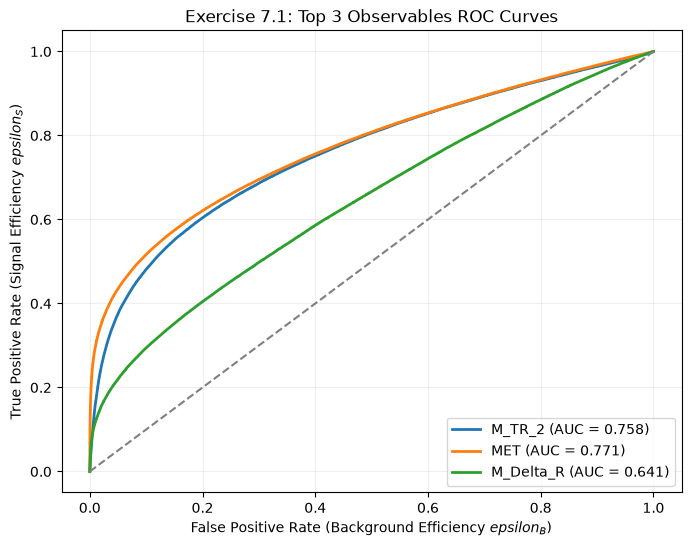

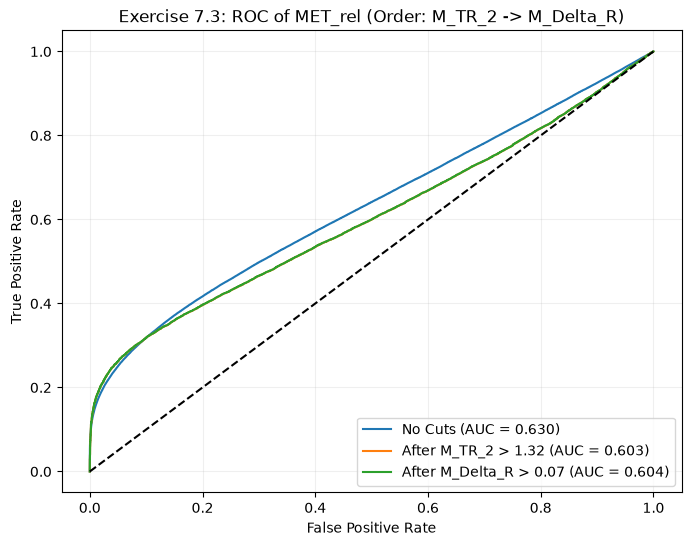

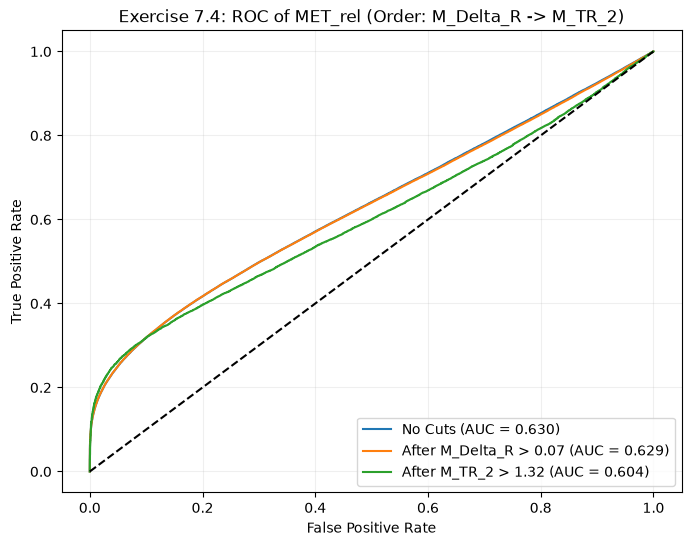

In [28]:

from sklearn.metrics import roc_curve, auc

def plot_roc_observables(df_data, var_list, mask=None, title="ROC Curves"):
    if mask is not None:
        data = df_data[mask]
    else:
        data = df_data
        
    y_true = data["signal"].to_numpy()
    plt.figure(figsize=(8, 6))
    
    for var in var_list:
        scores = data[var].to_numpy()
        fpr, tpr, _ = roc_curve(y_true, scores)
        roc_auc = auc(fpr, tpr)
        if roc_auc < 0.5:
            fpr, tpr, _ = roc_curve(y_true, -scores)
            roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{var} (AUC = {roc_auc:.3f})")
        
    plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
    plt.xlabel("False Positive Rate (Background Efficiency $epsilon_B$)")
    plt.ylabel("True Positive Rate (Signal Efficiency $epsilon_S$)")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.2)
    plt.show()


plot_roc_observables(df, ["M_TR_2", "MET", "M_Delta_R"], title="Exercise 7.1: Top 3 Observables ROC Curves")


def plot_successive_roc(df_data, eval_var, cut_sequence, title):
    plt.figure(figsize=(8, 6))
    mask = np.ones(len(df_data), dtype=bool)
    
   
    fpr, tpr, _ = roc_curve(df_data["signal"], df_data[eval_var])
    plt.plot(fpr, tpr, label=f"No Cuts (AUC = {auc(fpr, tpr):.3f})")
    
    for var in cut_sequence:
        xc = best_cuts_per_var[var][0]
        mask &= (df_data[var].to_numpy() > xc)
        sub = df_data[mask]
        fpr, tpr, _ = roc_curve(sub["signal"], sub[eval_var])
        plt.plot(fpr, tpr, label=f"After {var} > {xc:.2f} (AUC = {auc(fpr, tpr):.3f})")
        
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.2)
    plt.show()

plot_successive_roc(df, "MET_rel", ["M_TR_2", "M_Delta_R"], "Exercise 7.3: ROC of MET_rel (Order: M_TR_2 -> M_Delta_R)")
plot_successive_roc(df, "MET_rel", ["M_Delta_R", "M_TR_2"], "Exercise 7.4: ROC of MET_rel (Order: M_Delta_R -> M_TR_2)")

In [ ]:
#Intermediate ROC curves differ depending on which variable is cut first, because each cut sculpts the phase space differently according to 
#its correlation with MET_rel. However, once all rectangular cuts in the set (A AND B) are applied, the 
#final surviving subsample—and therefore the final ROC curve—is identical regardless of cut order because logical conjunction (AND) is commutative.

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

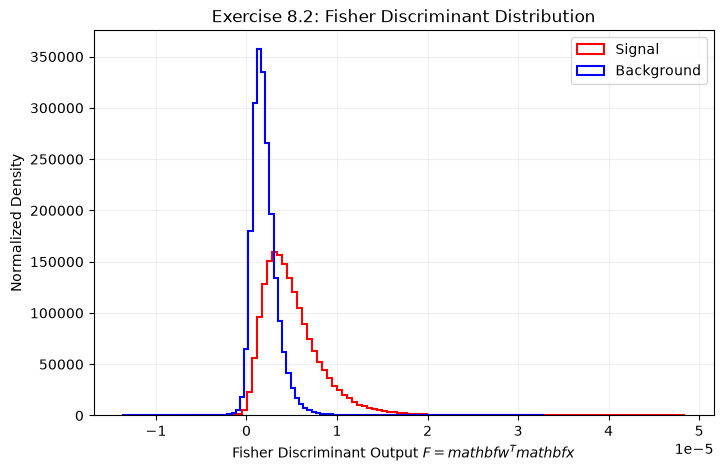

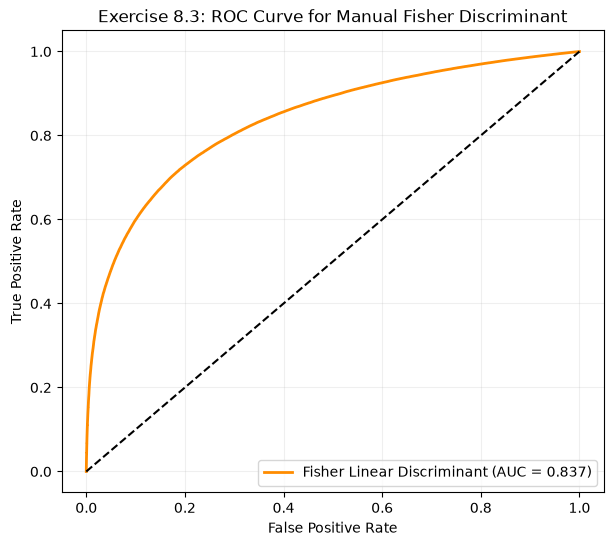

N_S,N_B,Optimal Cut,TPR (eps_S),FPR (eps_B),Max Significance
10,100,0,0.4916,0.0537,1.533
100,1000,0,0.4916,0.0537,4.846
1000,10000,0,0.4916,0.0537,15.326
10000,100000,0,0.4916,0.0537,48.464


In [30]:

X_sig = df_sig[VarNames[1:]].to_numpy()
X_bkg = df_bkg[VarNames[1:]].to_numpy()

m_sig = np.mean(X_sig, axis=0, keepdims=True).T  
m_bkg = np.mean(X_bkg, axis=0, keepdims=True).T  


diff_m = m_sig - m_bkg
S_B = diff_m @ diff_m.T


X_sig_centered = X_sig - m_sig.T
X_bkg_centered = X_bkg - m_bkg.T
S_W = (X_sig_centered.T @ X_sig_centered) + (X_bkg_centered.T @ X_bkg_centered)


w = np.linalg.inv(S_W) @ (m_sig - m_bkg) 

F_sig = (X_sig @ w).flatten()
F_bkg = (X_bkg @ w).flatten()

plt.figure(figsize=(8, 5))
plt.hist(F_sig, bins=100, histtype="step", color="red", label="Signal", density=True, lw=1.5)
plt.hist(F_bkg, bins=100, histtype="step", color="blue", label="Background", density=True, lw=1.5)
plt.xlabel("Fisher Discriminant Output $F = mathbf{w}^T mathbf{x}$")
plt.ylabel("Normalized Density")
plt.title("Exercise 8.2: Fisher Discriminant Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

F_all = df[VarNames[1:]].to_numpy() @ w
fpr_F, tpr_F, thresholds_F = roc_curve(df["signal"].to_numpy(), F_all.flatten())
auc_F = auc(fpr_F, tpr_F)

plt.figure(figsize=(7, 6))
plt.plot(fpr_F, tpr_F, color="darkorange", lw=2, label=f"Fisher Linear Discriminant (AUC = {auc_F:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 8.3: ROC Curve for Manual Fisher Discriminant")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.show()


fisher_sig_table = []
for Ns, Nb in scenarios:
    Ns_p = tpr_F * Ns
    Nb_p = fpr_F * Nb
    denom = np.sqrt(Ns_p + Nb_p)
    sigma_F = np.divide(Ns_p, denom, out=np.zeros_like(Ns_p), where=denom > 0)
    best_i = np.argmax(sigma_F)
    fisher_sig_table.append([Ns, Nb, f"{thresholds_F[best_i]:.5f}", f"{tpr_F[best_i]:.4f}", f"{fpr_F[best_i]:.4f}", f"{sigma_F[best_i]:.3f}"])

display(HTML("<h4>Exercise 8.4: Maximal Significance with Fisher Discriminant</h4>"))
display(HTML(tabulate.tabulate(fisher_sig_table, headers=["N_S", "N_B", "Optimal Cut", "TPR (eps_S)", "FPR (eps_B)", "Max Significance"], tablefmt="html")))